# Metagrating deflecting by 50°

Optimize the topology of a metagrating, a silicon grating on glass that bends light by 50°.

**Question.** A plane wave at 1.55 µm comes up through a glass substrate (index
1.444) and meets, at normal incidence, a grating of silicon (index 3.476) on the glass
surface. The grating has a period of $\Lambda = 2.023$ µm, and its lines run along y. Which
cross-section of the lines sends the most power into the air at 50° from the normal?

The direction is set by the period alone. The grating equation puts the $m$-th
transmitted order at $\sin\theta_m = m \lambda / \Lambda$ in air, so $\Lambda = \lambda / \sin 50^\circ$ gives the −1 order
50°. At this period only the orders −1, 0 and +1 propagate, in the air and in the
glass. How the power splits between them is the grating's cross-section, and that is
the design: two stacked layers of silicon, each 0.3 µm thick, whose pixels may each be
silicon or air.

We let gradients find it, as in the {doc}`bend tutorial <bend>`. The chain from pixels to
the objective is differentiable end to end:

pixels $\rho$ → **periodic Helmholtz filter** → **projection** → **layer grid** to the
mesh elements → **material field** $\varepsilon_r$ → {py:func}`gfem.solve` → the diffraction
efficiency of the −1 order.

The optimizer is [optax](https://optax.readthedocs.io)'s Adam.

**Assumptions.**

- One period of the grating, a cell periodic in x and in y (along the lines). The cell is
  0.08 µm thick along y, and nothing in it varies along y: the lines are infinitely long.
- The glass below and the air above are homogeneous, lossless half-spaces, with constant
  indices. Silicon is lossless too, with a constant index.
- The incident wave is TE (E along y) at normal incidence, so the cell is plainly
  periodic: no Bloch phase.
- {py:class}`gfem.FloquetPort` closes the cell on both open faces, one port per
  diffraction order and polarization. The ports of a face absorb every order at any angle,
  so the cell needs no PML, and $|S|^2$ of a port is that order's diffraction efficiency.
- The mesh (cells of at most 80 nm in the glass and the air, 25 nm × 50 nm in the design
  layers, second-order Nédélec elements) resolves the wavelength in silicon (0.45 µm).

In [1]:
import time
from pathlib import Path

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optax
from contourpy import contour_generator
from scipy.constants import c

import gfem
from gfem import design

um = 1e-6
WAVELENGTH = 1.55 * um
F0 = c / WAVELENGTH  # 193.4 THz
PERIOD = WAVELENGTH / np.sin(np.radians(50.0))  # 2.023 um

## The grating

The mesh is one period, 2.023 µm along x and 0.08 µm along y. From the bottom up its
volumes are `"glass"` (0.5 µm), the two design layers `"lower"` and `"upper"` (0.3 µm
each) and `"air"` (0.6 µm). Its surfaces are the open faces `"bottom"` (under the
glass) and `"top"` (over the air), and the four side faces `"x_min"`, `"x_max"`,
`"y_min"`, `"y_max"`, whose meshes are translates of each other. Each pair is one
{py:class}`gfem.Periodic` boundary. The cells are at most 80 nm in the glass and the
air. The design layers are meshed on a grid of 81 columns, one per pixel of the design
below (24.98 nm), and 6 rows of 50 nm per layer, so every design element lies inside
one pixel. The notebook reads the mesh from {download}`data/metagrating.msh`, built by
`tools/metagrating_mesh.py`.

The design layers start as air. Before any port is declared, the cell lists the
orders that propagate behind each open face:
{py:meth}`gfem.Model.propagating_orders` gives the orders $(m, n)$ on the lattice of the
two pairs, here $(m, 0)$ along x.

In [2]:
mesh = gfem.Mesh.from_gmsh(Path("data/metagrating.msh"), length_unit="um")
N_GLASS, N_SILICON = 1.444, 3.476
AIR = gfem.Material(name="air")
GLASS = gfem.Material(eps_r=N_GLASS**2, name="glass")
SILICON = gfem.Material(eps_r=N_SILICON**2, name="silicon")
LAYERS = ("lower", "upper")  # the design layers, bottom up

cell = gfem.Model(
    mesh,
    materials={"glass": GLASS, "lower": AIR, "upper": AIR, "air": AIR},
    boundaries=[gfem.Periodic(("x_min", "x_max")), gfem.Periodic(("y_min", "y_max"))],
)
print("orders propagating in the air (top):   ", cell.propagating_orders("top", F0))
print(
    "orders propagating in the glass (bottom):", cell.propagating_orders("bottom", F0)
)

orders propagating in the air (top):    ((0, 0), (-1, 0), (1, 0))
orders propagating in the glass (bottom): ((0, 0), (-1, 0), (1, 0))


One Floquet port per propagating order and polarization, on both faces: 12 ports. The
TE port of the specular order on the glass side is `"in"`, the incident wave; it also
measures the specular reflection. The other ports are named by face and order: `"T-1"`
is the −1 order transmitted into the air, `"R+1"` the +1 order reflected into the
glass, and a `" TM"` suffix marks the TM ports. Declaring every propagating order is
what makes the power balance below a check: an order without a port would be absorbed
but missing from S, and gfem would warn ({py:class}`gfem.UnrequestedOrderWarning`).

`offset` moves each port's reference plane towards the grating: the glass ports to the
glass surface, the air ports to the top of the grating. Offsets change the phases of S,
not its magnitudes.

In [3]:
GLASS_DEPTH, AIR_GAP = 0.5 * um, 0.6 * um  # from each open face to the grating


def floquet_ports(model, frequency):
    # A TE and a TM port for every order propagating on either face at `frequency`.
    ports = []
    for side, face, offset in (("R", "bottom", GLASS_DEPTH), ("T", "top", AIR_GAP)):
        for m, n in model.propagating_orders(face, frequency):
            label = f"{side}{m:+d}" if m else f"{side}0"
            for polarization in ("TE", "TM"):
                name = label if polarization == "TE" else f"{label} TM"
                if name == "R0":
                    name = "in"  # the incident wave, and the specular reflection
                ports.append(
                    gfem.FloquetPort(
                        name,
                        face,
                        order=(m, n),
                        polarization=polarization,
                        offset=offset,
                    )
                )
    return ports


grating = cell.replace(ports=floquet_ports(cell, F0))
print([port.name for port in grating.ports])

['in', 'R0 TM', 'R-1', 'R-1 TM', 'R+1', 'R+1 TM', 'T0', 'T0 TM', 'T-1', 'T-1 TM', 'T+1', 'T+1 TM']


**Before optimizing, the bare interface.** With both design layers air, the cell is a
flat glass-air interface, and its reflection has a closed form. At normal incidence the
reflection coefficient of the tangential electric field, at the interface, is
$(n_\mathrm{glass} - 1)/(n_\mathrm{glass} + 1) = +0.1817$ for both polarizations (the sign convention is in
{py:mod}`gfem.conventions`). A flat interface diffracts nothing, so every
non-specular row of S reads 0, and the transmitted power is $1 - 0.1817^2$.

One driven problem at 1.55 µm with `excite="in"` feeds the incident port and gives the
column of S it drives, one entry per port. A direct solver suits the repeated solves
below.

In [4]:
options = gfem.SolverOptions(linear_solver="direct")
problem = gfem.Driven(frequency=F0, excite="in")
bare = gfem.solve(grating, problem, options=options).s

r_closed = (N_GLASS - 1) / (N_GLASS + 1)
s_bare = complex(bare["in", "in"][0])
non_specular = max(
    abs(complex(bare[port.name, "in"][0]))
    for port in grating.ports
    if port.order != (0, 0)
)
t_bare = abs(complex(bare["T0", "in"][0])) ** 2
print(f"S[in, in] = {s_bare:.5f}, closed form (n - 1)/(n + 1) = {r_closed:+.5f}")
print(f"|S[T0, in]|^2 = {t_bare:.5f}, closed form 1 - r^2 = {1 - r_closed**2:.5f}")
print(f"largest non-specular |S|: {non_specular:.1e}")

S[in, in] = 0.18167+0.00001j, closed form (n - 1)/(n + 1) = +0.18167
|S[T0, in]|^2 = 0.96700, closed form 1 - r^2 = 0.96700
largest non-specular |S|: 9.0e-07


## From pixels to a material

Each design layer has its own **layer grid**: 81 pixels of 24.98 nm along x, a pitch that
divides the period, and 4 rows along y. `periodic=(True, False)` tells the grid that its
two x edges are one seam of the periodic cell, so the filter smooths across it and the
design has no edge at $x = 0$. The lines are invariant along y, so the design is one row
of pixels per layer, $\rho$ of shape (2, 81), broadcast over the rows.

`physical` maps the design parameters to the density the solve sees, per layer:

1. **Broadcast** the layer's row over the 4 rows.
2. **Helmholtz filter** of radius 0.1 µm, periodic along x: a length scale of about
   0.1 µm.
3. **Projection** towards 0 (air) or 1 (silicon) at threshold 0.5, with a sharpness $\beta$
   that the optimization raises step by step.

Each mesh element of a layer takes the bilinear interpolation of its grid at its
centroid, and the material field interpolates $\varepsilon_r$ linearly between air and
silicon. The mesh's columns are the pixels, so each element sits inside one pixel.

In [5]:
PITCH = PERIOD / 81


def layer_grids(mesh):
    return {
        name: design.LayerGrid(mesh, name, pitch=PITCH, periodic=(True, False))
        for name in LAYERS
    }


grids = layer_grids(mesh)
blur = {
    name: design.helmholtz_filter(grid, radius=0.1 * um) for name, grid in grids.items()
}


def physical(rho, beta):
    # Design parameters (2, 81) -> physical density (2, 81): broadcast, filter, project.
    rows = [
        design.project(blur[name](jnp.broadcast_to(row, grids[name].shape)), beta)[0]
        for name, row in zip(LAYERS, rho, strict=True)
    ]
    return jnp.stack(rows)


def with_design(model, density, grids=grids):
    # The model with each design layer's permittivity from its row of density.
    for name, row in zip(LAYERS, density, strict=True):
        field = grids[name].to_elements(jnp.broadcast_to(row, grids[name].shape))
        model = model.with_material(
            name, gfem.MaterialField.interpolate(field, AIR, SILICON)
        )
    return model


def s_matrix(density, model=grating, problem=problem, grids=grids):
    return gfem.solve(with_design(model, density, grids), problem, options=options).s


grids["lower"]

LayerGrid('lower', pitch=2.498e-08 m, shape=(4, 81), periodic=(True, False), 5832 elements)

## The objective

The objective is the diffraction efficiency of the −1 transmitted order, $\eta = |S|^2$ of
port `"T-1"` fed from `"in"`: the share of the incident power that leaves into the air
at 50° with E along the lines. The loss minimized is $1 - \eta$. An efficiency in dB would
be $-\infty$ wherever $\eta$ is exactly 0, with a NaN gradient; take dB after optimizing.

The start matters. A design uniform along x is a flat layer, which diffracts nothing:
$\eta = 0$, and since the gradient of $|S|^2$ is $2\,\mathrm{Re}(S^* \partial S)$, it
vanishes too. A uniform start is a stationary point. The optimization starts from a linear
ramp instead, $\rho = x/\Lambda$ in both layers: a staircase blaze, which already leans
towards one side. The two starts, side by side:

In [6]:
def loss(rho, beta):
    eta = jnp.abs(s_matrix(physical(rho, beta))["T-1", "in"][0]) ** 2
    return 1 - eta, eta  # missed power; aux: the efficiency


value_and_grad = jax.jit(jax.value_and_grad(loss, has_aux=True))

ramp = np.broadcast_to((np.arange(81) + 0.5) / 81, (2, 81))
starts = {"uniform 0.5": np.full((2, 81), 0.5), "ramp x / period": ramp}
for name, start in starts.items():
    (_, eta_start), g_start = value_and_grad(jnp.asarray(start), 1.0)
    size = float(jnp.linalg.norm(g_start))
    print(f"{name:16s}: eta = {float(eta_start):.2e}, |gradient| = {size:.2e}")

uniform 0.5     : eta = 5.99e-14, |gradient| = 1.80e-07


ramp x / period : eta = 1.39e-01, |gradient| = 2.84e-01


From the uniform start, $\eta$ and its gradient are zero up to round-off (10⁻¹³ and
10⁻⁷): Adam would not move. The ramp starts at $\eta = 0.139$, with a gradient of order 1.

## The gradient against finite differences

The gradient passes through the solve's adjoint, the material field, the layer grids,
the periodic filter and the projection. A central difference along one random unit
direction of the pixels, with a step of 10⁻⁴, checks it at the ramp start projected at
$\beta = 4$.

In [7]:
rho_check = jnp.asarray(ramp)
direction = np.random.default_rng(1).standard_normal((2, 81))
direction /= np.linalg.norm(direction)
(j_check, _), g_check = value_and_grad(rho_check, 4.0)
along = float(jnp.sum(g_check * direction))
step = 1e-4
j_plus = float(loss(rho_check + step * direction, 4.0)[0])
j_minus = float(loss(rho_check - step * direction, 4.0)[0])
difference = (j_plus - j_minus) / (2 * step)
fd_error = abs(along - difference) / abs(difference)
print(f"objective at the ramp, beta = 4: {float(j_check):.6f}")
print(f"gradient along the direction:   {along:+.9e}")
print(f"central difference (step 1e-4): {difference:+.9e}")
print(f"relative difference: {fd_error:.1e}")

objective at the ramp, beta = 4: 0.992359
gradient along the direction:   +1.629230780e-02
central difference (step 1e-4): +1.629230765e-02
relative difference: 9.3e-09


The adjoint gradient and the difference agree to about 10⁻⁸, the difference's own
truncation and round-off.

## Optimize

Adam on the raw pixels with step 0.1, clipped to [0, 1], from the ramp. The projection
sharpness $\beta$ doubles from 1 to 32 every 8 steps (continuation), 48 iterations in all,
each one driven solve and its gradient. At normal incidence the cell is plainly
periodic, so the adjoint solve reuses the forward factorization. The loop keeps four
snapshots of the physical density, at iterations 0, 16, 31 and 47.

In [8]:
BETAS, STEPS_PER_BETA = (1.0, 2.0, 4.0, 8.0, 16.0, 32.0), 8
n_steps = len(BETAS) * STEPS_PER_BETA
snapshot_at = [round(i * (n_steps - 1) / 3) for i in range(4)]  # 0, 16, 31, 47
rho = jnp.asarray(ramp)
optimizer = optax.adam(0.1)
state = optimizer.init(rho)
history, snapshots = [], {}
tic = time.perf_counter()
for beta in BETAS:
    for _ in range(STEPS_PER_BETA):
        (_, eta), g = value_and_grad(rho, beta)
        if len(history) in snapshot_at:
            snapshots[len(history)] = np.asarray(physical(rho, beta))
        updates, state = optimizer.update(g, state)
        rho = jnp.clip(optax.apply_updates(rho, updates), 0.0, 1.0)
        history.append(float(eta))
    print(f"beta = {beta:4.0f}: eta = {history[-1]:.4f}")
print(f"{n_steps} iterations in {time.perf_counter() - tic:.0f} s")

beta =    1: eta = 0.4429


beta =    2: eta = 0.7656


beta =    4: eta = 0.9092


beta =    8: eta = 0.8765


beta =   16: eta = 0.9462


beta =   32: eta = 0.9573
48 iterations in 849 s


$\eta$ per iteration; the thin grey lines mark where $\beta$ doubles. $\eta$ climbs to 0.957 at
$\beta = 32$. Each doubling of $\beta$ sharpens the projection, which changes the design the solver
sees, and $\eta$ can drop for a few steps before Adam recovers, as at iteration 24.

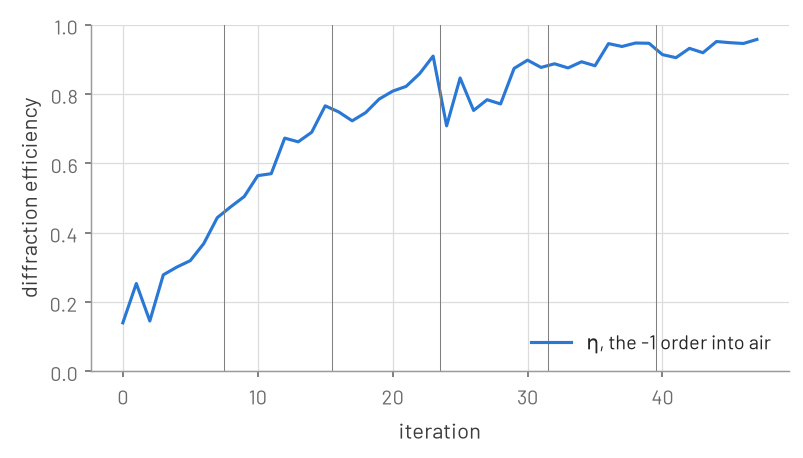

In [9]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(history, label="η, the -1 order into air")
for k in range(STEPS_PER_BETA, n_steps, STEPS_PER_BETA):
    ax.axvline(k - 0.5, color="gray", lw=0.5)
ax.set_ylim(0, 1)
ax.set_xlabel("iteration")
ax.set_ylabel("diffraction efficiency")
ax.legend(loc="lower right");

## The design

The cross-section $(x, z)$ of one period at the four snapshots: white silicon, black
air, the glass dark grey below. The ramp's two staircases break up into silicon blocks
of a few tens to a few hundred nanometres, and the blocks of the two layers are offset
from each other: together they form a blazed profile that leans towards $-x$, the side
of the −1 order.

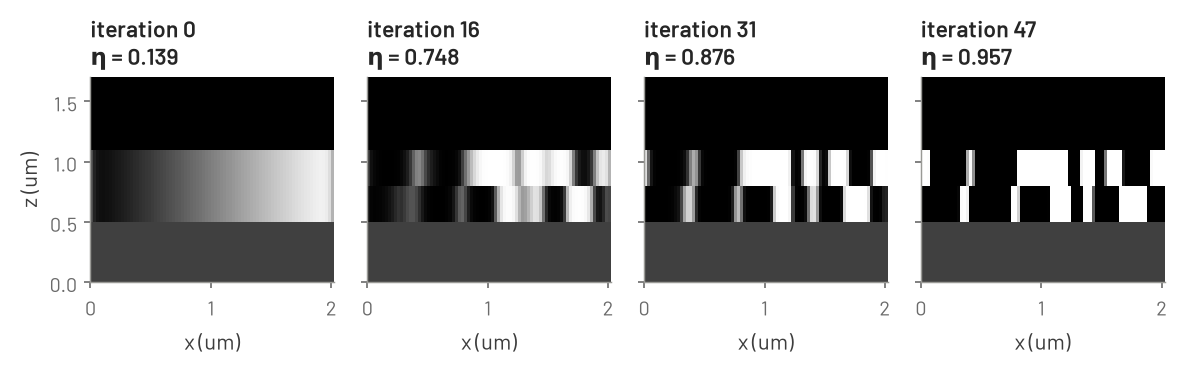

In [10]:
Z_ROWS = 0.05 * um  # the cross-section image's row height
HEIGHTS = {"glass": 0.5 * um, "lower": 0.3 * um, "upper": 0.3 * um, "air": 0.6 * um}
GLASS_GREY = 0.25
TOP = sum(HEIGHTS.values())
SECTION_EXTENT = np.array([0, PERIOD, 0, TOP]) / um


def section(density):
    # The cell's (x, z) cross-section as a pixel image, rows of 0.05 um bottom up.
    fills = {"glass": GLASS_GREY, "lower": density[0], "upper": density[1], "air": 0.0}
    rows = []
    for name, height in HEIGHTS.items():
        rows += [np.broadcast_to(fills[name], (81,))] * round(height / Z_ROWS)
    return np.array(rows)


fig, axes = plt.subplots(1, 4, figsize=(8, 2.6), sharey=True)
for ax, k in zip(axes, snapshot_at, strict=True):
    ax.imshow(
        section(snapshots[k]),
        origin="lower",
        extent=SECTION_EXTENT,
        cmap="gray",
        vmin=0,
        vmax=1,
    )
    ax.set_title(f"iteration {k}\nη = {history[k]:.3f}")
    ax.set_xlabel("x (um)")
axes[0].set_ylabel("z (um)")
fig.tight_layout();

The design we evaluate is `final`: the last physical density thresholded at 0.5, all
silicon or air. Every number after this comes from it. At $\beta = 32$, 96 % of the pixels
are already within 0.05 of 0 or 1; the rest lie on the block edges, and thresholding
them moves $\eta$ from 0.957 to 0.900 (below).

In [11]:
last = physical(rho, BETAS[-1])
final = (last > 0.5).astype(float)
binary = float(jnp.mean((last < 0.05) | (last > 0.95)))
print(f"iteration {n_steps - 1}: eta = {history[-1]:.4f} at beta = {BETAS[-1]:.0f}")
print(f"{100 * binary:.1f} % of the pixels lie within 0.05 of 0 or 1")
fill = np.asarray(final).mean(axis=1)
print(f"silicon fill: lower layer {fill[0]:.1%}, upper {fill[1]:.1%}")

iteration 47: eta = 0.9573 at beta = 32
96.3 % of the pixels lie within 0.05 of 0 or 1
silicon fill: lower layer 30.9%, upper 46.9%


## Where the power goes

One solve of `final` at 1.55 µm gives every order's efficiency. The media are
lossless, so the efficiencies of all propagating orders, both faces and both
polarizations, must add up to 1. The incident wave is TE and nothing varies along y,
so the TM ports should read 0: there is no cross-polarization. The solve also feeds
the air side's +1 order, `"T+1"`, for the reciprocity check below, and keeps the
fields.

In [12]:
trust = gfem.solve(
    with_design(grating, final),
    gfem.Driven(frequency=F0, excite=("in", "T+1"), keep_fields=F0),
    options=options,
)
orders = trust.diffraction_orders
efficiency = {
    port.name: abs(complex(trust.s[port.name, "in"][0])) ** 2 for port in grating.ports
}
eta_final = efficiency["T-1"]
balance = abs(1 - sum(efficiency.values()))
cross_polarization = max(e for name, e in efficiency.items() if name.endswith("TM"))
print("port    order  angle (deg)  efficiency")
for name, eta in efficiency.items():
    if not name.endswith("TM"):
        theta = np.degrees(float(orders[name].theta[0]))
        print(f"{name:6s}  {orders[name].order!s:7s} {theta:8.1f}     {eta:.4f}")
print(f"largest TM efficiency: {cross_polarization:.1e}")
print(f"power balance: 1 - sum |S|^2 = {1 - sum(efficiency.values()):+.1e}")

port    order  angle (deg)  efficiency
in      (0, 0)       0.0     0.0114
R-1     (-1, 0)     32.0     0.0220
R+1     (1, 0)      32.0     0.0167
T0      (0, 0)       0.0     0.0217
T-1     (-1, 0)     50.0     0.9001
T+1     (1, 0)      50.0     0.0281
largest TM efficiency: 8.3e-06
power balance: 1 - sum |S|^2 = +1.9e-05


The orders as arrows from the grating, at each order's angle from
`diffraction_orders[...].theta`, labelled with its efficiency: transmitted into the air
above, reflected into the glass below, and the incident wave coming up from below.

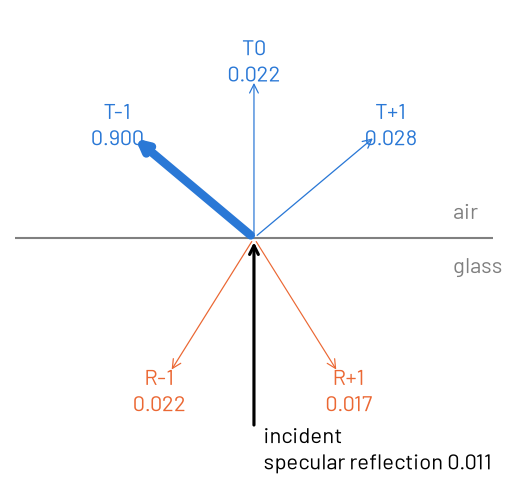

In [13]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.axhline(0, color="gray", lw=1)
ax.annotate(
    "", xy=(0, 0), xytext=(0, -1.2), arrowprops=dict(arrowstyle="->", color="k", lw=1.5)
)
ax.text(
    0.06,
    -1.15,
    f"incident\nspecular reflection {efficiency['in']:.3f}",
    color="k",
    va="top",
)
for name, eta in efficiency.items():
    if name == "in" or name.endswith("TM"):
        continue
    up = 1 if name.startswith("T") else -1
    theta = float(orders[name].theta[0])
    side = np.sign(float(orders[name].wave_vector[0][0]))
    tip = np.array([side * np.sin(theta), up * np.cos(theta)])
    colour = "C0" if up > 0 else "C1"
    ax.annotate(
        "",
        xy=tip,
        xytext=(0, 0),
        arrowprops=dict(arrowstyle="->", color=colour, lw=0.5 + 4 * eta),
    )
    ax.text(*(1.12 * tip), f"{name}\n{eta:.3f}", color=colour, ha="center", va="center")
ax.text(1.25, 0.12, "air", color="gray")
ax.text(1.25, -0.22, "glass", color="gray")
ax.set_xlim(-1.5, 1.5)
ax.set_ylim(-1.5, 1.4)
ax.set_aspect("equal")
ax.axis("off");

`final` sends 0.900 of the incident power into the −1 order at 50°. Of the rest, 0.050
leaves into the air in the 0 and +1 orders and 0.050 is reflected into the glass,
0.011 of it specularly. The efficiencies add up to 1 to within 2 × 10⁻⁵, and the TM
ports read at most 10⁻⁵: the cell's mesh is not exactly mirror-symmetric in y, so the
polarizations decouple only to within the discretization.

## Reciprocity and the order labels

The media are reciprocal, but for Floquet ports the plain transpose $S_{pq} = S_{qp}$ does
not hold: reversing a wave reverses its in-plane wave vector, so order $m$ becomes
order $-m$, and an order whose in-plane wave vector is not zero takes a sign. With
$\sigma = -1$ for such an order and +1 for the specular one
({py:mod}`gfem.conventions`), reciprocity reads

$$
S_{p\leftarrow q} = \sigma_p \sigma_q S_{-q\leftarrow -p}.
$$

Here $p = \mathrm{T}{-}1$ and $q = \mathrm{in}$, so $S[\mathrm{in}, \mathrm{T}{+}1] = -S[\mathrm{T}{-}1, \mathrm{in}]$.
At normal incidence the discrete system is symmetric, so the identity holds for the
discrete model to round-off; the plain transpose misses by $2|S|$, about 1.9.

In [14]:
s_forward = complex(trust.s["T-1", "in"][0])
s_backward = complex(trust.s["in", "T+1"][0])
reciprocity = abs(s_backward + s_forward)
print(f"S[T-1, in] = {s_forward:.5f}")
print(f"S[in, T+1] = {s_backward:.5f}")
print(f"|S[in, T+1] + S[T-1, in]| = {reciprocity:.1e}")
transpose = abs(s_backward - s_forward)
print(f"|S[in, T+1] - S[T-1, in]| = {transpose:.3f}, the plain transpose")

S[T-1, in] = -0.31712-0.89416j
S[in, T+1] = 0.31712+0.89416j
|S[in, T+1] + S[T-1, in]| = 1.3e-15
|S[in, T+1] - S[T-1, in]| = 1.897, the plain transpose


## The field

$E_y$ at $t = 0$, $\mathrm{Re}(E_y)$, over three periods of the cross-section ($y = 0.04$ µm), with 1 W
incident from the glass. The cell is plainly periodic, so the field of one period
repeats unchanged. Below the grating, the incident wave and its reflections; above it,
phase fronts tilted by 50°: the −1 order. The blue line is the silicon edge.

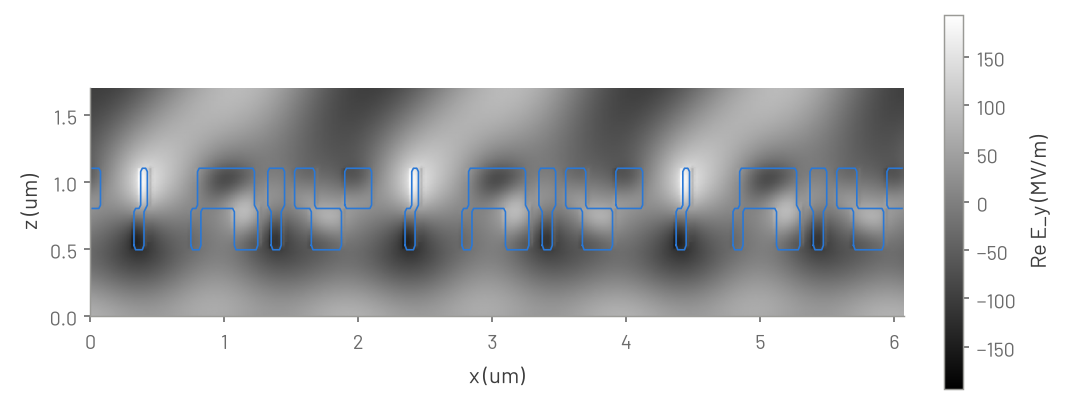

In [15]:
e_in = trust.e_field(F0, excite="in")
nx, nz = 120, 170
xs = (np.arange(nx) + 0.5) / nx * PERIOD
zs = (np.arange(nz) + 0.5) / nz * TOP
X, Z = np.meshgrid(xs, zs)
plane = np.stack([X.ravel(), np.full(X.size, 0.04 * um), Z.ravel()], axis=1)
ey = np.real(np.asarray(e_in.at(plane))[:, 1]).reshape(X.shape) / 1e6  # MV/m
periods = 3
tiled = np.tile(ey, (1, periods))
peak = np.abs(tiled).max()
fig, ax = plt.subplots(figsize=(7, 2.6), layout="constrained")
image = ax.imshow(
    tiled,
    origin="lower",
    extent=[0, periods * PERIOD / um, 0, TOP / um],
    cmap="gray",
    vmin=-peak,
    vmax=peak,
)
image_x = (np.arange(81 * periods) + 0.5) * PITCH / um
image_z = (np.arange(round(TOP / Z_ROWS)) + 0.5) * Z_ROWS / um
silicon = np.tile(section(final), (1, periods))
for line in contour_generator(image_x, image_z, silicon).lines(0.5):
    ax.plot(*line.T, color="C0", ls="-", lw=0.8)
ax.set_xlabel("x (um)")
ax.set_ylabel("z (um)")
ax.grid(False)
fig.colorbar(image, ax=ax, label="Re E_y (MV/m)");

## The spectrum

The objective sees one wavelength. A uniform sweep of 9 wavelengths, 1.45 to 1.65 µm,
shows what the design does around it. Below 1.461 µm, $n_\mathrm{glass} \Lambda / 2$, the glass's
$(\pm 2, 0)$ orders start to propagate: a **Rayleigh anomaly** inside the band. For the
power balance to stay a check across the band, the sweep's model declares those
orders too: `floquet_ports` over all the wavelengths lists every order that propagates
at any of them. At the wavelengths where an order does not propagate, its rows read
exactly 0, and `diffraction_orders` says so.

In [16]:
wavelengths = np.linspace(1.45, 1.65, 9) * um
band = cell.replace(ports=floquet_ports(cell, c / wavelengths))
print(
    "orders in the glass over the band:",
    cell.propagating_orders("bottom", c / wavelengths),
)
spectrum = gfem.solve(
    with_design(band, final),
    gfem.Driven(frequency=c / wavelengths, excite="in"),
    options=options,
)
band_power = {
    port.name: np.abs(np.asarray(spectrum.s[port.name, "in"])) ** 2
    for port in band.ports
}
eta_band = band_power["T-1"]
glass_2 = band_power["R-2"] + band_power["R+2"]
band_balance = np.abs(1 - sum(band_power.values()))
open_2 = np.asarray(spectrum.diffraction_orders["R-2"].propagating)
anomaly = N_GLASS * PERIOD / 2
print(f"Rayleigh anomaly of the glass's (+-2, 0) orders: {anomaly / um:.4f} um")
print(f"band: max |1 - sum |S|^2| = {band_balance.max():.1e}")
print("wavelength (um)  eta(T-1)  R+-2 power  R+-2 propagate")
for lam, eta, r2, is_open in zip(
    wavelengths / um, eta_band, glass_2, open_2, strict=True
):
    print(f"{lam:15.3f}  {eta:8.4f}  {r2:10.4f}  {bool(is_open)}")

orders in the glass over the band: ((0, 0), (-1, 0), (1, 0), (-2, 0), (2, 0))


Rayleigh anomaly of the glass's (+-2, 0) orders: 1.4609 um
band: max |1 - sum |S|^2| = 2.4e-05
wavelength (um)  eta(T-1)  R+-2 power  R+-2 propagate
          1.450    0.3935      0.0632  True
          1.475    0.4409      0.0000  False
          1.500    0.5136      0.0000  False
          1.525    0.7778      0.0000  False
          1.550    0.9001      0.0000  False
          1.575    0.7454      0.0000  False
          1.600    0.6327      0.0000  False
          1.625    0.5146      0.0000  False
          1.650    0.2766      0.0000  False


$\eta$ of the −1 order (solid) and the power in the glass's $(\pm 2, 0)$ orders (dashed)
against wavelength. The dotted line marks the Rayleigh anomaly, the dash-dotted one
1.55 µm. $\eta$ peaks at the design wavelength and falls to 0.39 at 1.45 µm and 0.28 at
1.65 µm. At 1.45 µm, below the anomaly, the glass's $(\pm 2, 0)$ orders carry 0.063 of the
power; above it their rows read 0. The efficiencies add up to 1 to within 10⁻⁴ at every
wavelength.

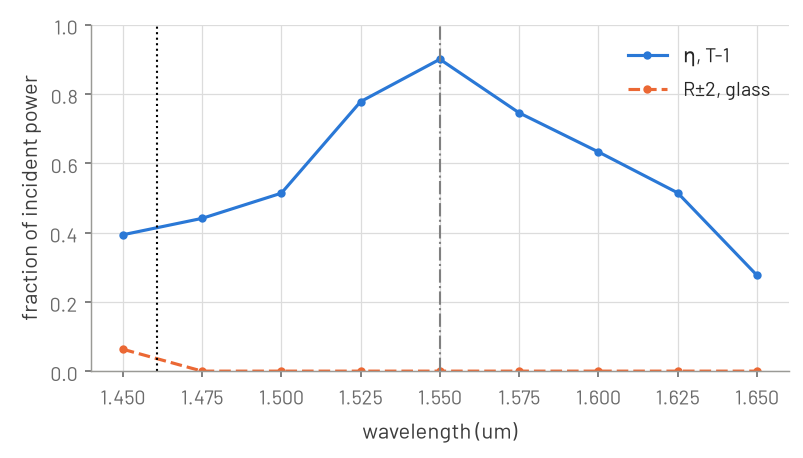

In [17]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(wavelengths / um, eta_band, marker="o", ms=3, label="η, T-1")
ax.plot(wavelengths / um, glass_2, ls="--", marker="o", ms=3, label="R±2, glass")
ax.axvline(anomaly / um, color="k", ls=":", lw=1)
ax.axvline(WAVELENGTH / um, color="gray", ls="-.", lw=1)
ax.set_ylim(0, 1)
ax.set_xlabel("wavelength (um)")
ax.set_ylabel("fraction of incident power")
ax.legend(loc="upper right");

## A finer mesh

{download}`data/metagrating_fine.msh` is the same cell with cells of at most 60 nm in
the glass and the air, and 12 rows of 25 nm per design layer. Its layer grids have the
same pixels, so `final` applies as it is. The columns are the same 81 pixels, so the
elements sample the same pixel image: the re-solve bounds the field's discretization
error, not a change of design. $\eta$ moves by 3 × 10⁻⁴.

In [18]:
mesh_fine = gfem.Mesh.from_gmsh(Path("data/metagrating_fine.msh"), length_unit="um")
fine = gfem.Model(
    mesh_fine, materials=cell.materials, boundaries=cell.boundaries, ports=grating.ports
)
s_fine = s_matrix(final, model=fine, grids=layer_grids(mesh_fine))
eta_fine = abs(complex(s_fine["T-1", "in"][0])) ** 2
print(f"50 nm rows, 80 nm cells: eta = {eta_final:.4f}")
delta_mesh = eta_fine - eta_final
print(f"25 nm rows, 60 nm cells: eta = {eta_fine:.4f}, delta = {delta_mesh:+.1e}")

50 nm rows, 80 nm cells: eta = 0.9001
25 nm rows, 60 nm cells: eta = 0.9004, delta = +3.2e-04


## Checks

| check | value | asserted |
| --- | --- | --- |
| bare interface, reflection; non-specular rows | 0.1817; 0 | to $10^{-3}$; below $10^{-5}$ |
| power balance; reciprocity of `final` | printed above | below $10^{-4}$ |
| gradient against a difference | about $10^{-8}$ | below $10^{-6}$ |
| $\eta$ of `final` | 0.900 | at least 0.8; to 0.005 |
| $\eta$ of the last iterate | 0.957 | to 0.005 |
| mesh change | $3 \times 10^{-4}$ | below $2 \times 10^{-3}$ |
| band power balance | $10^{-4}$ | below $10^{-4}$ |
| glass $(\pm 2, 0)$ orders at 1.45 µm | 0.063 | to 0.005 |

## Limits

- **Infinitely long lines.** The cell is invariant along y; a finite grating diffracts in
  y as well.
- **One polarization, one angle, one wavelength.** The objective is TE at normal incidence
  at 1.55 µm; $\eta$ falls to 0.28 at 1.65 µm. A broadband design sums the objective over
  wavelengths, as the {doc}`topology tutorial <topology>` does.
- **Constant, lossless indices.** Silicon's dispersion and absorption are left out; a
  lossy or dispersive layer belongs inside the cell.
- **The mesh is part of the material model.** Each element takes the pixel image at its
  centroid. A mesh whose elements straddle pixel edges samples another design, and with
  elements larger than the pixels the efficiency can move by several hundredths: mesh the
  design region on the pixel grid, or finer, before trusting the second digit.
- **A length scale from the filter only.** The 0.1 µm filter gives no guaranteed minimum
  feature, and the two layers are taken as perfectly aligned.
  {doc}`../recipes/robust-optimization` adds eroded and dilated designs to the loop.

## Next

- {doc}`../recipes/floquet-ports`: oblique incidence, angles fixed over a band, TM and
  circular polarization, a fed cell, and the checks of a Floquet model.
- {doc}`../recipes/periodic-cell`: periodic pairs and Bloch wave vectors.
- {py:mod}`gfem.conventions`: the lattice frame, the TE/TM references and the sign of
  a Floquet S entry.
- {doc}`bend`: the same optimization loop on a waveguide bend.

In [19]:
np.testing.assert_allclose(s_bare, 0.1817, atol=1e-3)
np.testing.assert_array_less(non_specular, 1e-5)
np.testing.assert_array_less(balance, 1e-4)
np.testing.assert_array_less(reciprocity, 1e-4)
np.testing.assert_array_less(fd_error, 1e-6)
np.testing.assert_array_less(0.8, eta_final)
np.testing.assert_allclose(eta_final, 0.900, atol=0.005)
np.testing.assert_allclose(history[-1], 0.957, atol=0.005)
np.testing.assert_array_less(abs(delta_mesh), 2e-3)
np.testing.assert_array_less(band_balance.max(), 1e-4)
np.testing.assert_allclose(glass_2[0], 0.063, atol=0.005)